# Treasury Market-Basket Analysis — Approach 5: Co-occurrence Graph + Whitespace Gap

## Purpose

Two lenses on the treasury service baskets that are **not** rule mining:

- **A. Co-occurrence graph analysis** — treat services as nodes and co-purchase
  strength as edge weight, then ask structural questions (centrality, communities,
  threshold stability). This is included for methodological completeness; on this
  snapshot it is *uninformative by construction* and the notebook says so at every step.
- **B. Whitespace / gap analysis** — a peer-relative completeness view. For each
  relationship, which services do its peers hold that it does not? This needs **no
  support threshold and no significance test**, so it is the one technique of the five
  that still returns a defensible answer at n = 9.

## Data source (pinned)

`PL_DATA_STUDIO.DERIVED.CORE_TREASURY_ACCOUNTS_MONTHLY`, pinned to
`VERSION_PARTITION = '2.5'` and `DATE_PARTITION = '2026-08-31'` (see the parameter
cell). Service-group names are recovered by a pre-deduplicated join to
`PL_DATA_STUDIO.INTEGRATION_TESTING."TreasuryServices_Prod_7-1-26"`; that dimension
lives in an integration-testing schema, so the group mapping is **provisional**.
All loading and metric primitives come from `mba_common.py` — nothing is re-derived here.

## Graph constructions and measures

| Construction | Nodes | Edges | Edge weight |
|---|---|---|---|
| Service co-occurrence graph (projected, one-mode) | 11 services | one per co-occurring service pair | `EDGE_WEIGHT` ∈ {`lift`, `jaccard`, `cooccurrence`} |
| Bipartite relationship↔service graph | 9 relationships + 11 services | relationship holds service | 1 (unweighted incidence) |
| Bipartite → service projection | 11 services | shared relationships | count of shared relationships |

| Measure | Question it answers | Behaviour on a near-complete graph |
|---|---|---|
| Degree centrality (weighted) | how broadly a service co-occurs | ≈ constant, uninformative |
| Betweenness centrality | brokerage between otherwise-separated services | **0 for every node** — no node is on any unique shortest path |
| Eigenvector centrality | connection to well-connected nodes | ≈ 1/√n for all nodes; power iteration may fail to converge |
| Greedy-modularity communities | natural service clusters | arbitrary partition of a clique |
| Basket completeness (whitespace) | share of peer-available services held | **informative — degrades gracefully at small n** |

## Degeneracy warning — read before any output below

Per `GROUND_TRUTH.md`: there are **9 baskets and 11 services**, and **9 of the 11
services appear in every single basket**. Consequences for this notebook specifically:

1. The co-occurrence graph is a **near-clique**: every service pair co-occurs, so the
   graph is complete (55 of 55 possible edges) and almost every edge weight is exactly
   `1.0` under lift. Lift can only ever take the values `1.0` or `1.125` here.
2. **Centrality measures on a near-complete graph are essentially uniform and carry no
   information.** Ranking services by centrality on this data would be a presentation
   artefact, not a finding. The values are shown precisely so their flatness is visible.
3. **Community detection on a near-clique returns an arbitrary partition**, not
   discovered communities. Re-running with a different tie-break order can return a
   different partition of equal modularity.
4. The **only genuine, defensible finding in this dataset** is that *OBX Integrated &
   Co.* is the sole relationship missing `Incoming Foreign` and `Outgoing Foreign` while
   all 8 peers hold both. That is **one observation at n = 9** — a lead to verify, not a
   validated pattern, and it carries no statistical support.

In [1]:
"""Robust import of mba_common for local and in-Snowflake execution."""
import sys
from pathlib import Path

try:
    import mba_common
except ModuleNotFoundError:
    _candidates = [
        str(Path.cwd()),
        str(Path(globals().get("__vsc_ipynb_file__", "x")).parent),
        "/home/udf/notebook",
        "/tmp/notebook",
    ]
    for _p in _candidates:
        if _p and _p not in sys.path:
            sys.path.insert(0, _p)
    try:
        import mba_common
    except ModuleNotFoundError as exc:  # pragma: no cover - environment issue
        raise ModuleNotFoundError(
            "mba_common.py was not importable. Upload mba_common.py alongside "
            "this notebook (same directory / same Snowflake stage) and re-run. "
            f"Searched sys.path entries: {_candidates}"
        ) from exc

print("mba_common loaded from", mba_common.__file__)

mba_common loaded from /Users/jeisenman/ra/qtwo_bench/investigations/treasury_mba/mba_common.py


## Parameters

Single clearly marked cell — everything downstream reads from here.

In [2]:
# ---------------------------------------------------------------- PARAMETERS
VERSION_PARTITION = "2.5"            # pinned snapshot version
DATE_PARTITION = "2026-08-31"        # pinned snapshot date
EDGE_WEIGHT = "lift"                 # "lift" | "jaccard" | "cooccurrence"
EDGE_THRESHOLDS = (0.0, 0.5, 1.0, 1.1)   # weight floors for the stability panel
LAYOUT_SEED = 20261014               # deterministic spring-layout seed
ITEM_GRAIN = mba_common.ITEM_SERVICE  # ITEM_SERVICE (11 items) or ITEM_GROUP (all NULL)
# ---------------------------------------------------------------------------

import itertools
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print(f"networkx {nx.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

networkx 3.2.1 | pandas 2.3.3 | numpy 1.26.1


## Load the pinned snapshot and quantify the degeneracy

`mba_common.degeneracy_report` is the authoritative summary of how much usable
co-occurrence variation exists. Everything in Part A must be read through it.

In [3]:
snapshot = mba_common.load_snapshot(VERSION_PARTITION, DATE_PARTITION)
matrix = snapshot.basket_matrix(ITEM_GRAIN)
support = mba_common.item_support(matrix)

# RELATIONSHIP_ID -> human-readable name, for labelling.
names = (
    snapshot.rows[[mba_common.BASKET_KEY, "RELATIONSHIP_NAME"]]
    .drop_duplicates()
    .set_index(mba_common.BASKET_KEY)["RELATIONSHIP_NAME"]
)
labels = {rid: str(names.get(rid, rid)) for rid in matrix.index}

print(f"baskets={snapshot.n_baskets}  items={matrix.shape[1]}  grain={ITEM_GRAIN}")
print("\nItem support:")
print(support.to_frame("support").round(3))

baskets=9  items=11  grain=TREASURY_SERVICE_NAME

Item support:
                       support
TREASURY_SERVICE_NAME         
Checks Deposited         1.000
Debits                   1.000
Incoming Domestic        1.000
Items Deposited          1.000
Monthly Servicing        1.000
Outgoing Domestic        1.000
Retail Item              1.000
Wholesale Deposit        1.000
Wholesale Item           1.000
Incoming Foreign         0.889
Outgoing Foreign         0.889


In [4]:
report = mba_common.degeneracy_report(matrix)
display(
    pd.Series(
        {
            "n_baskets": report["n_baskets"],
            "n_items": report["n_items"],
            "distinct_basket_signatures": report["distinct_baskets"],
            "n_universal_items": len(report["universal_items"]),
            "distinct_lift_values": report["distinct_lift_values"],
            "is_degenerate": report["is_degenerate"],
            "min_detectable_support_delta": round(
                mba_common.min_detectable_support_delta(report["n_baskets"]), 4
            ),
        },
        name="degeneracy_report",
    ).to_frame()
)
print("universal items (in every basket):")
for item in report["universal_items"]:
    print("  -", item)

,degeneracy_report
n_baskets,9
n_items,11
distinct_basket_signatures,2
n_universal_items,9
distinct_lift_values,"[1.0, 1.125]"
is_degenerate,False
min_detectable_support_delta,0.1111


universal items (in every basket):
  - Checks Deposited
  - Debits
  - Incoming Domestic
  - Items Deposited
  - Monthly Servicing
  - Outgoing Domestic
  - Retail Item
  - Wholesale Deposit
  - Wholesale Item


**Reading the report.** `distinct_basket_signatures = 2` means the 9 relationships
collapse into only two distinct purchase patterns: "all 11 services" (8 relationships)
and "all but the two foreign-wire services" (1 relationship). The entire dataset
therefore contains **one bit** of differential information. `distinct_lift_values`
confirms lift can only be `1.0` or `1.125`. Nothing in Part A can escape this.

---
# Part A — Co-occurrence graph analysis

## A.1 Building the weighted service graph

Edge weights come from `mba_common.pair_metrics`, so the graph is a re-encoding of the
same primitives used by the other notebooks — not a second, independent calculation.

In [5]:
pairs = mba_common.pair_metrics(matrix)
print(f"{len(pairs)} unordered pairs out of "
      f"{matrix.shape[1] * (matrix.shape[1] - 1) // 2} possible")
display(pairs[["antecedent", "consequent", "cooccurrence", "support",
               "lift", "jaccard"]].head(12).round(4))

print("\nvalue counts of each candidate edge weight:")
for col in ("lift", "jaccard", "cooccurrence"):
    counts = pairs[col].round(6).value_counts().sort_index()
    print(f"  {col:13s}: " + ", ".join(f"{v}×{int(c)}" for v, c in counts.items()))

55 unordered pairs out of 55 possible


,antecedent,consequent,cooccurrence,support,lift,jaccard
0,Incoming Foreign,Outgoing Foreign,8,0.8889,1.125,1.0
1,Checks Deposited,Debits,9,1.0000,1.000,1.0
2,Checks Deposited,Incoming Domestic,9,1.0000,1.000,1.0
3,Checks Deposited,Items Deposited,9,1.0000,1.000,1.0
4,Checks Deposited,Monthly Servicing,9,1.0000,1.000,1.0
5,Checks Deposited,Outgoing Domestic,9,1.0000,1.000,1.0
6,Checks Deposited,Retail Item,9,1.0000,1.000,1.0
7,Checks Deposited,Wholesale Deposit,9,1.0000,1.000,1.0
8,Checks Deposited,Wholesale Item,9,1.0000,1.000,1.0
9,Debits,Incoming Domestic,9,1.0000,1.000,1.0



value counts of each candidate edge weight:
  lift         : 1.0×54, 1.125×1
  jaccard      : 0.888889×18, 1.0×37
  cooccurrence : 8×19, 9×36


In [6]:
def build_service_graph(pair_frame, weight=EDGE_WEIGHT, threshold=0.0):
    """Weighted one-mode service co-occurrence graph.

    Args:
        pair_frame: Output of ``mba_common.pair_metrics``.
        weight: Column used as the edge weight.
        threshold: Keep edges whose weight is >= this value.

    Returns:
        An undirected ``networkx.Graph`` with ``weight`` edge attributes and
        ``support`` node attributes.
    """
    if weight not in pair_frame.columns:
        raise KeyError(f"unknown edge weight column: {weight!r}")
    graph = nx.Graph()
    for item, value in support.items():
        graph.add_node(item, support=float(value))
    kept = pair_frame[
        (pair_frame[weight] >= threshold) & (pair_frame["cooccurrence"] > 0)
    ]
    for row in kept.itertuples(index=False):
        graph.add_edge(
            row.antecedent, row.consequent, weight=float(getattr(row, weight))
        )
    return graph


G = build_service_graph(pairs)
density = nx.density(G)
print(f"nodes={G.number_of_nodes()}  edges={G.number_of_edges()}  "
      f"density={density:.3f}  complete={density == 1.0}")
print(f"is_connected={nx.is_connected(G)}  diameter={nx.diameter(G)}")
print("\nThe graph is a COMPLETE graph (density 1.0, diameter 1): every service "
      "co-occurs with every other service in at least one basket.")

nodes=11  edges=55  density=1.000  complete=True
is_connected=True  diameter=1

The graph is a COMPLETE graph (density 1.0, diameter 1): every service co-occurs with every other service in at least one basket.


### Figure 1 — the co-occurrence network

Node size is proportional to item support; edge width is proportional to edge weight.
Layout uses the fixed `LAYOUT_SEED` so the drawing is reproducible.

Note what the picture shows: a **clique**. There is no modular structure, no periphery
and no bridge. The only visual asymmetry is the two slightly smaller foreign-wire nodes.

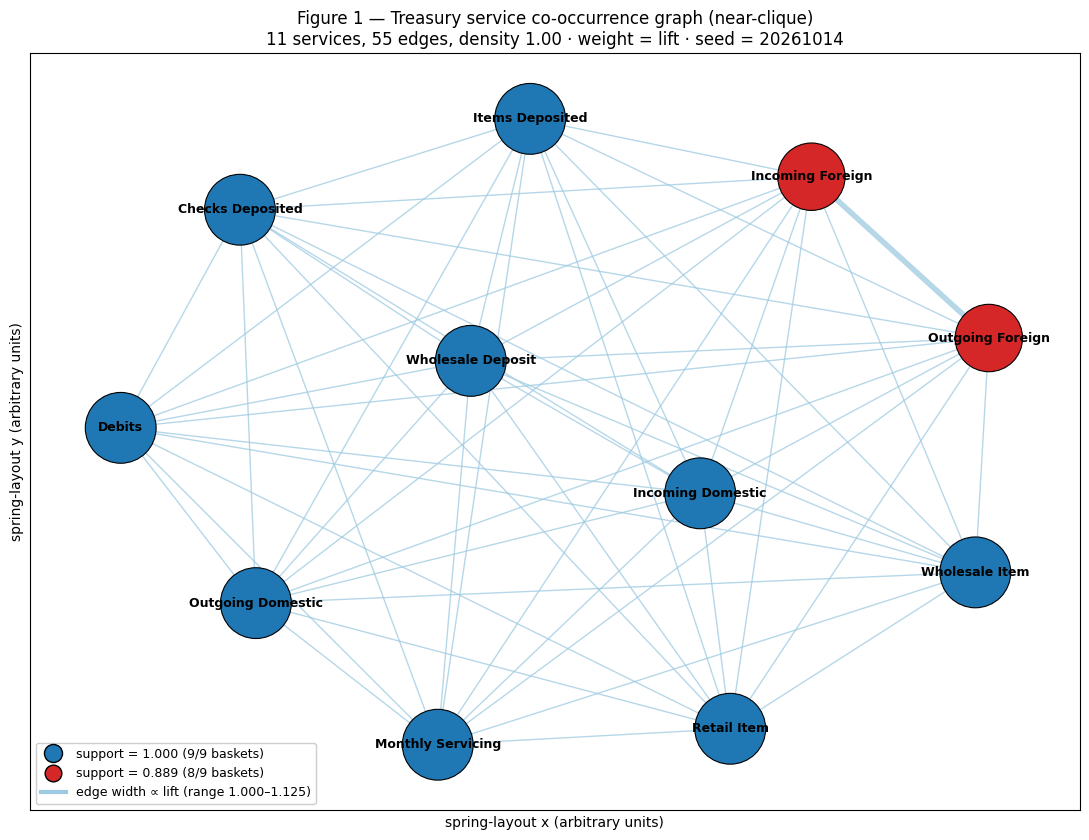

In [7]:
pos = nx.spring_layout(G, seed=LAYOUT_SEED, weight="weight")
weights = np.array([G[u][v]["weight"] for u, v in G.edges()])
node_support = np.array([G.nodes[n]["support"] for n in G.nodes()])
is_gap_service = np.array([G.nodes[n]["support"] < 1.0 for n in G.nodes()])

fig, ax = plt.subplots(figsize=(11, 8.5))
nx.draw_networkx_edges(
    G, pos, ax=ax, width=1.0 + 3.0 * (weights - weights.min()) / max(weights.ptp(), 1e-9),
    edge_color="#9ecae1", alpha=0.75,
)
nx.draw_networkx_nodes(
    G, pos, ax=ax, node_size=400 + 2200 * node_support,
    node_color=np.where(is_gap_service, "#d62728", "#1f77b4"),
    edgecolors="black", linewidths=0.8,
)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9, font_weight="bold")
handles = [
    plt.Line2D([], [], marker="o", color="w", markerfacecolor="#1f77b4",
               markeredgecolor="black", markersize=13, label="support = 1.000 (9/9 baskets)"),
    plt.Line2D([], [], marker="o", color="w", markerfacecolor="#d62728",
               markeredgecolor="black", markersize=12, label="support = 0.889 (8/9 baskets)"),
    plt.Line2D([], [], color="#9ecae1", lw=3,
               label=f"edge width ∝ {EDGE_WEIGHT} (range "
                     f"{weights.min():.3f}–{weights.max():.3f})"),
]
ax.legend(handles=handles, loc="lower left", fontsize=9, framealpha=0.95)
ax.set_title(
    "Figure 1 — Treasury service co-occurrence graph (near-clique)\n"
    f"{G.number_of_nodes()} services, {G.number_of_edges()} edges, density "
    f"{density:.2f} · weight = {EDGE_WEIGHT} · seed = {LAYOUT_SEED}",
    fontsize=12,
)
ax.set_xlabel("spring-layout x (arbitrary units)")
ax.set_ylabel("spring-layout y (arbitrary units)")
ax.set_axis_on()
ax.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

### A.2 Threshold stability — the structure does not change

Normally one prunes weak edges to reveal structure. Here lift takes only two values
(`1.0`, `1.125`), so **every threshold up to 1.0 keeps all 55 edges** and any threshold
above 1.0 keeps only the single foreign-wire edge. There is no intermediate regime,
i.e. nothing to tune and nothing to discover.

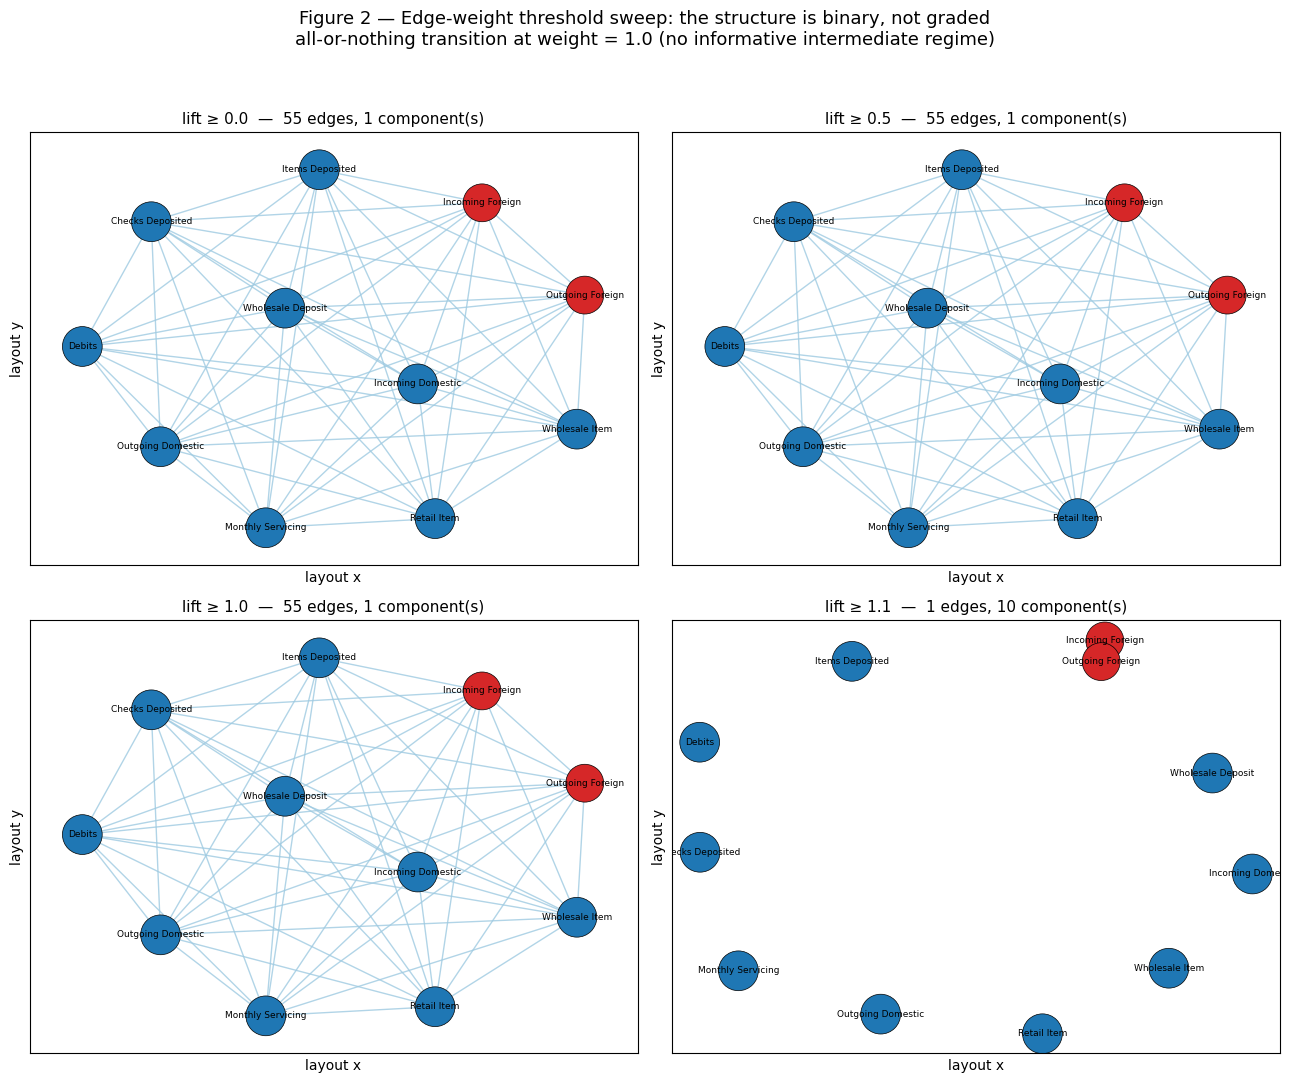

,threshold,edges_kept,edge_fraction,components,isolated_nodes
0,0.0,55,1.000,1,0
1,0.5,55,1.000,1,0
2,1.0,55,1.000,1,0
3,1.1,1,0.018,10,9


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
rows = []
for ax, threshold in zip(axes.ravel(), EDGE_THRESHOLDS):
    sub = build_service_graph(pairs, threshold=threshold)
    sub_pos = nx.spring_layout(sub, seed=LAYOUT_SEED, weight="weight")
    n_comp = nx.number_connected_components(sub)
    rows.append(
        {
            "threshold": threshold,
            "edges_kept": sub.number_of_edges(),
            "edge_fraction": sub.number_of_edges() / max(G.number_of_edges(), 1),
            "components": n_comp,
            "isolated_nodes": sum(1 for _, d in sub.degree() if d == 0),
        }
    )
    nx.draw_networkx_edges(sub, sub_pos, ax=ax, edge_color="#9ecae1", alpha=0.8)
    nx.draw_networkx_nodes(
        sub, sub_pos, ax=ax,
        node_size=120 + 700 * np.array([sub.nodes[n]["support"] for n in sub.nodes()]),
        node_color=["#d62728" if sub.nodes[n]["support"] < 1.0 else "#1f77b4"
                    for n in sub.nodes()],
        edgecolors="black", linewidths=0.5,
    )
    nx.draw_networkx_labels(sub, sub_pos, ax=ax, font_size=6.5)
    ax.set_title(f"{EDGE_WEIGHT} ≥ {threshold}  —  {sub.number_of_edges()} edges, "
                 f"{n_comp} component(s)", fontsize=11)
    ax.set_xlabel("layout x")
    ax.set_ylabel("layout y")
    ax.tick_params(labelsize=7)
fig.suptitle(
    "Figure 2 — Edge-weight threshold sweep: the structure is binary, not graded\n"
    "all-or-nothing transition at weight = 1.0 (no informative intermediate regime)",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

threshold_table = pd.DataFrame(rows)
display(threshold_table.round(3))

### A.3 Centrality — shown to demonstrate that it is uninformative

**Do not read the ranking below as a finding.** On a complete graph:

- degree centrality is identical for every node (all 1.0 unweighted);
- **betweenness centrality is exactly 0 for every node** — with diameter 1, every
  shortest path is a single edge, so no node brokers anything;
- eigenvector centrality is ≈ 1/√n for all nodes, and power iteration can fail to
  converge on a regular graph. We catch that explicitly and fall back to the dense
  eigen-decomposition (`eigenvector_centrality_numpy`), then to a documented uniform
  vector if that also fails.

The useful output of this section is the **spread** column: it is ~0, which is the
quantitative statement that centrality carries no information here.

In [9]:
def eigenvector_with_fallback(graph, weight="weight"):
    """Eigenvector centrality with a documented fallback chain.

    Power iteration frequently fails on regular / near-complete graphs. Order:
    power iteration -> dense numpy eigensolver -> uniform 1/sqrt(n) vector.

    Returns:
        ``(centrality_dict, method_name)``.
    """
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return (
                nx.eigenvector_centrality(
                    graph, max_iter=1000, tol=1e-8, weight=weight
                ),
                "power_iteration",
            )
    except (nx.PowerIterationFailedConvergence, nx.NetworkXException) as exc:
        print(f"  power iteration failed ({type(exc).__name__}); using numpy solver")
    try:
        return nx.eigenvector_centrality_numpy(graph, weight=weight), "numpy_eigensolver"
    except Exception as exc:  # noqa: BLE001 - last-resort documented fallback
        print(f"  numpy eigensolver failed ({type(exc).__name__}); using uniform vector")
        n = graph.number_of_nodes()
        uniform = 1.0 / np.sqrt(n) if n else 0.0
        return {node: uniform for node in graph.nodes()}, "uniform_fallback"


eig, eig_method = eigenvector_with_fallback(G)
centrality = pd.DataFrame(
    {
        "support": support.reindex(list(G.nodes())),
        "degree": pd.Series(nx.degree_centrality(G)),
        "weighted_degree": pd.Series(dict(G.degree(weight="weight")))
        / max(1, G.number_of_nodes() - 1),
        "betweenness": pd.Series(nx.betweenness_centrality(G, weight="weight")),
        "eigenvector": pd.Series(eig),
        "clustering": pd.Series(nx.clustering(G, weight="weight")),
    }
).sort_index()
print(f"eigenvector method used: {eig_method}")
display(centrality.round(6))

spread = pd.DataFrame(
    {
        "min": centrality.min(),
        "max": centrality.max(),
        "spread (max-min)": centrality.max() - centrality.min(),
        "std": centrality.std(),
    }
)
display(spread.round(6))
print(
    "Every centrality measure has a spread of ~0 (betweenness is identically 0).\n"
    "CONCLUSION: centrality is degenerate on this graph and must NOT be used to\n"
    "rank services. The only column with any variation is `support`, and its\n"
    "variation is the single foreign-wire gap, not a centrality effect."
)

eigenvector method used: power_iteration


,support,degree,weighted_degree,betweenness,eigenvector,clustering
Checks Deposited,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Debits,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Incoming Domestic,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Incoming Foreign,0.888889,1.0,1.0125,0.0,0.304332,0.896007
Items Deposited,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Monthly Servicing,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Outgoing Domestic,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Outgoing Foreign,0.888889,1.0,1.0125,0.0,0.304332,0.896007
Retail Item,1.000000,1.0,1.0000,0.0,0.300881,0.889680
Wholesale Deposit,1.000000,1.0,1.0000,0.0,0.300881,0.889680


,min,max,spread (max-min),std
support,0.888889,1.000000,0.111111,0.044947
degree,1.000000,1.000000,0.000000,0.000000
weighted_degree,1.000000,1.012500,0.012500,0.005056
betweenness,0.000000,0.000000,0.000000,0.000000
eigenvector,0.300881,0.304332,0.003451,0.001396
clustering,0.889680,0.896007,0.006328,0.002560


Every centrality measure has a spread of ~0 (betweenness is identically 0).
CONCLUSION: centrality is degenerate on this graph and must NOT be used to
rank services. The only column with any variation is `support`, and its
variation is the single foreign-wire gap, not a centrality effect.


### Figure 3 — centrality comparison

Each measure is plotted on its own native scale. The bars are flat by construction;
that flatness *is* the result.

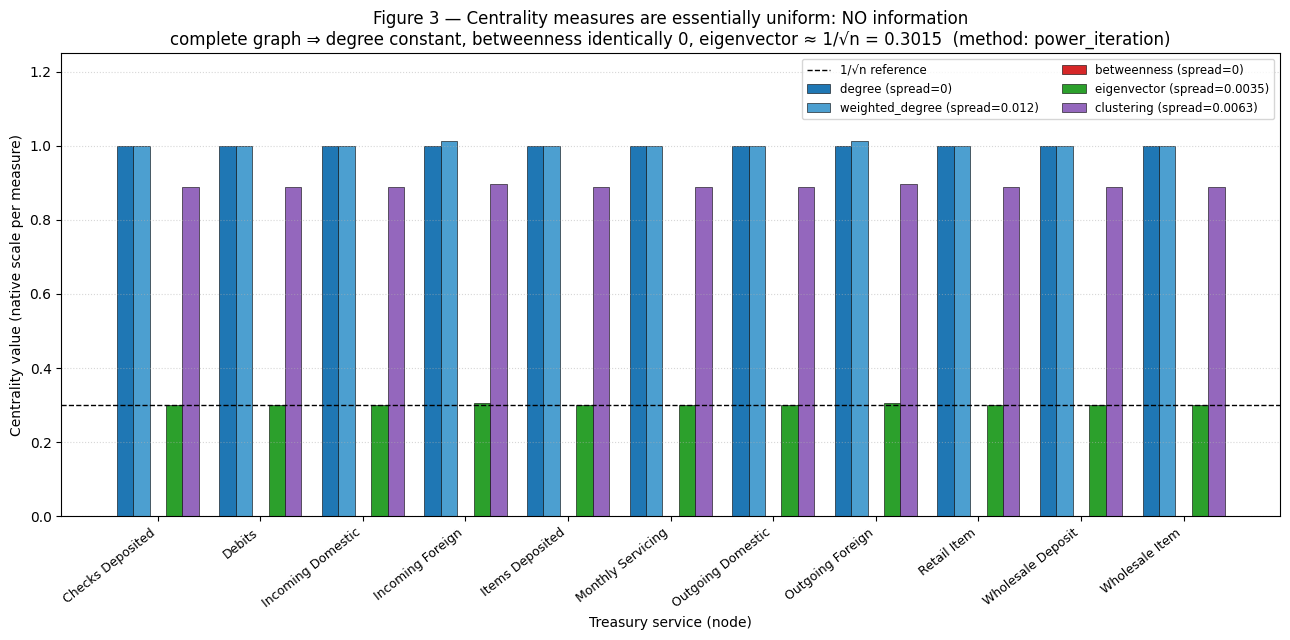

In [10]:
measures = ["degree", "weighted_degree", "betweenness", "eigenvector", "clustering"]
items = list(centrality.index)
x = np.arange(len(items))
width = 0.16
colors = ["#1f77b4", "#4c9fd0", "#d62728", "#2ca02c", "#9467bd"]

fig, ax = plt.subplots(figsize=(13, 6.5))
for offset, (measure, color) in enumerate(zip(measures, colors)):
    ax.bar(x + (offset - 2) * width, centrality[measure], width,
           label=f"{measure} (spread={centrality[measure].max() - centrality[measure].min():.2g})",
           color=color, edgecolor="black", linewidth=0.4)
ax.set_xticks(x)
ax.set_xticklabels(items, rotation=38, ha="right", fontsize=9)
ax.set_xlabel("Treasury service (node)")
ax.set_ylabel("Centrality value (native scale per measure)")
ax.set_title(
    "Figure 3 — Centrality measures are essentially uniform: NO information\n"
    "complete graph ⇒ degree constant, betweenness identically 0, "
    f"eigenvector ≈ 1/√n = {1 / np.sqrt(len(items)):.4f}  (method: {eig_method})",
    fontsize=12,
)
ax.axhline(1 / np.sqrt(len(items)), ls="--", lw=1.0, color="black",
           label="1/√n reference")
ax.legend(fontsize=8.5, ncol=2, loc="upper right")
ax.grid(axis="y", ls=":", alpha=0.5)
ax.set_ylim(0, 1.25)
fig.tight_layout()
plt.show()

### A.4 Community detection — an arbitrary partition, not a discovery

Greedy modularity maximisation on a clique has no non-trivial optimum: modularity is
~0 for every partition, so the algorithm returns whatever its tie-break order produces.
Read the output immediately below as **an artefact of the algorithm**, not as service
clusters that exist in the business.

In [11]:
communities = list(
    nx.algorithms.community.greedy_modularity_communities(G, weight="weight")
)
modularity = nx.algorithms.community.modularity(G, communities, weight="weight")
print(f"greedy modularity: {len(communities)} community(ies), "
      f"modularity Q = {modularity:.6f}")
for idx, community in enumerate(communities, start=1):
    print(f"  community {idx}: {sorted(community)}")

has_louvain = hasattr(nx.algorithms.community, "louvain_communities")
print(f"\nlouvain available in networkx {nx.__version__}: {has_louvain}")
if has_louvain:
    louvain = nx.algorithms.community.louvain_communities(
        G, weight="weight", seed=LAYOUT_SEED
    )
    print(f"  louvain: {len(louvain)} community(ies), "
          f"Q = {nx.algorithms.community.modularity(G, louvain, weight='weight'):.6f}")
    for idx, community in enumerate(louvain, start=1):
        print(f"    community {idx}: {sorted(community)}")

print(
    "\nINTERPRETATION: Q ≈ 0 means the partition explains no more edge concentration\n"
    "than chance. On a near-clique any partition is as good as any other, so these\n"
    "groupings are ARBITRARY. They are not discovered communities and must not be\n"
    "presented as service segments."
)

greedy modularity: 1 community(ies), modularity Q = 0.000000
  community 1: ['Checks Deposited', 'Debits', 'Incoming Domestic', 'Incoming Foreign', 'Items Deposited', 'Monthly Servicing', 'Outgoing Domestic', 'Outgoing Foreign', 'Retail Item', 'Wholesale Deposit', 'Wholesale Item']

louvain available in networkx 3.2.1: True
  louvain: 1 community(ies), Q = 0.000000
    community 1: ['Checks Deposited', 'Debits', 'Incoming Domestic', 'Incoming Foreign', 'Items Deposited', 'Monthly Servicing', 'Outgoing Domestic', 'Outgoing Foreign', 'Retail Item', 'Wholesale Deposit', 'Wholesale Item']

INTERPRETATION: Q ≈ 0 means the partition explains no more edge concentration
than chance. On a near-clique any partition is as good as any other, so these
groupings are ARBITRARY. They are not discovered communities and must not be
presented as service segments.


### A.5 Bipartite relationship↔service graph and its projection

The bipartite view keeps relationships and services as separate node sets. Projecting
onto services gives edge weights equal to the number of shared relationships — the raw
co-occurrence count. It reproduces the same near-clique, which is a useful consistency
check: the degeneracy is a property of the data, not of one graph construction.

In [12]:
B = nx.Graph()
B.add_nodes_from(matrix.index, bipartite=0, kind="relationship")
B.add_nodes_from(matrix.columns, bipartite=1, kind="service")
for rid in matrix.index:
    for service in matrix.columns[matrix.loc[rid]]:
        B.add_edge(rid, service)

print(f"bipartite: {B.number_of_nodes()} nodes "
      f"({matrix.shape[0]} relationships + {matrix.shape[1]} services), "
      f"{B.number_of_edges()} edges")
print(f"bipartite density = "
      f"{nx.algorithms.bipartite.density(B, set(matrix.index)):.4f} "
      f"(1.0 would mean every relationship holds every service)")

service_proj = nx.algorithms.bipartite.weighted_projected_graph(B, set(matrix.columns))
rel_proj = nx.algorithms.bipartite.weighted_projected_graph(B, set(matrix.index))
proj_weights = pd.Series(
    {f"{u} | {v}": d["weight"] for u, v, d in service_proj.edges(data=True)}
)
print(f"\nservice projection: {service_proj.number_of_edges()} edges, "
      f"weight distribution = {proj_weights.value_counts().sort_index().to_dict()}")
print(f"relationship projection: {rel_proj.number_of_edges()} edges, "
      f"all weights ∈ {sorted({d['weight'] for _, _, d in rel_proj.edges(data=True)})} "
      "(shared-service counts — every relationship pair shares ≥ 9 services)")
print(
    "\nThe projection is again complete. Two edge weights only (8 and 9), matching\n"
    "the two basket signatures. Same single bit of information, different encoding."
)

bipartite: 20 nodes (9 relationships + 11 services), 97 edges
bipartite density = 0.9798 (1.0 would mean every relationship holds every service)

service projection: 55 edges, weight distribution = {8: 19, 9: 36}
relationship projection: 36 edges, all weights ∈ [9, 11] (shared-service counts — every relationship pair shares ≥ 9 services)

The projection is again complete. Two edge weights only (8 and 9), matching
the two basket signatures. Same single bit of information, different encoding.


---
# Part B — Whitespace / gap analysis

**This is the only part of the notebook that produces a usable answer.**

The construction: for each relationship *r* and service *s* that *r* does not hold,
compute the **peer adoption rate** — the fraction of the *other* 8 relationships that
do hold *s*. A gap with high peer adoption is a candidate cross-sell; a gap with low
peer adoption is probably just a different business mix.

Why this works at n = 9 when rule mining does not: it makes **no distributional claim**.
There is no support threshold to clear, no lift to compare against a null, and no
p-value. It is a descriptive completeness statement about individual relationships —
"8 of your 8 peers hold this and you do not" — which remains well-defined and auditable
however small the panel is. The inference it supports is correspondingly modest: it
identifies *where to look*, not *what will convert*.

In [13]:
def whitespace_table(basket_matrix, name_map):
    """Per-(relationship, missing service) gaps with peer adoption rates.

    Peer adoption excludes the focal relationship, so the rate is a genuine
    leave-one-out peer statistic rather than overall support.

    Returns:
        DataFrame sorted by peer adoption then relationship.
    """
    n = len(basket_matrix)
    if n < 2:
        raise ValueError("whitespace analysis needs at least 2 baskets")
    holders = basket_matrix.sum(axis=0)
    records = []
    for rid in basket_matrix.index:
        row = basket_matrix.loc[rid]
        for service in basket_matrix.columns[~row]:
            peers = int(holders[service])  # focal does not hold it, so no subtraction
            records.append(
                {
                    "relationship_id": rid,
                    "relationship_name": name_map[rid],
                    "missing_service": service,
                    "peer_holders": peers,
                    "peer_total": n - 1,
                    "peer_adoption_rate": peers / (n - 1),
                }
            )
    if not records:
        return pd.DataFrame(
            columns=["relationship_id", "relationship_name", "missing_service",
                     "peer_holders", "peer_total", "peer_adoption_rate"]
        )
    return pd.DataFrame(records).sort_values(
        ["peer_adoption_rate", "relationship_name"], ascending=[False, True],
        ignore_index=True,
    )


gaps = whitespace_table(matrix, labels)
print(f"total whitespace cells: {len(gaps)} out of "
      f"{matrix.size} relationship×service cells "
      f"({len(gaps) / matrix.size:.1%} of the grid)")
display(gaps.round(3))

total whitespace cells: 2 out of 99 relationship×service cells (2.0% of the grid)


,relationship_id,relationship_name,missing_service,peer_holders,peer_total,peer_adoption_rate
0,025d8b3e-d123-42a7-9a04-2e604484193c,OBX Integrated & Co.,Incoming Foreign,8,8,1.0
1,025d8b3e-d123-42a7-9a04-2e604484193c,OBX Integrated & Co.,Outgoing Foreign,8,8,1.0


In [14]:
completeness = pd.DataFrame(
    {
        "relationship_name": [labels[r] for r in matrix.index],
        "services_held": matrix.sum(axis=1).astype(int),
        "services_available": matrix.shape[1],
    },
    index=matrix.index,
)
completeness["basket_completeness"] = (
    completeness["services_held"] / completeness["services_available"]
)
completeness["n_gaps"] = (
    completeness["services_available"] - completeness["services_held"]
)
completeness = completeness.sort_values(
    ["basket_completeness", "relationship_name"], ascending=[True, True]
)
display(completeness.round(4))

print("Next-best-service recommendation per relationship "
      "(highest peer adoption first):")
if gaps.empty:
    print("  none — every relationship holds every service")
else:
    for rid, group in gaps.groupby("relationship_id", sort=False):
        ranked = group.sort_values("peer_adoption_rate", ascending=False)
        head = ranked.iloc[0]
        rest = ", ".join(
            f"{r.missing_service} ({r.peer_adoption_rate:.0%})"
            for r in ranked.iloc[1:].itertuples(index=False)
        )
        print(f"  {head.relationship_name}: 1) {head.missing_service} "
              f"({head.peer_holders}/{head.peer_total} peers = "
              f"{head.peer_adoption_rate:.0%})"
              + (f"; then {rest}" if rest else ""))
complete_rels = completeness.index[completeness["n_gaps"] == 0]
print(f"\n{len(complete_rels)} of {len(completeness)} relationships have a complete "
      "basket (no whitespace at all).")

,relationship_name,services_held,services_available,basket_completeness,n_gaps
RELATIONSHIP_ID,,,,,
025d8b3e-d123-42a7-9a04-2e604484193c,OBX Integrated & Co.,9,11,0.8182,2
5cc9db33-b27c-48a8-b7d0-d69aa632f092,Acme Supply Inc. - Integrated,11,11,1.0000,0
7638e194-7916-4fae-879c-22a95fbccc57,"Bohannon Development, LLC",11,11,1.0000,0
901ba45b-5481-4a03-86b8-67f961665011,Cape Lookout Marine,11,11,1.0000,0
9858122e-0494-4b9a-b5bf-45eea25773b2,Cape Lookout Marine V3,11,11,1.0000,0
47102bd7-e025-4f4c-9634-d5de8c27ee25,Cape Lookout Marine V4,11,11,1.0000,0
257bd20b-c38f-4726-87ce-a4cc9ed0df58,Charles & Laura Design Studios,11,11,1.0000,0
38550f29-8fca-49f4-be49-56e0a7e7e8e0,Coastal Realty & Co.,11,11,1.0000,0
e53e199b-ef9b-4bc6-b709-452bb6b52514,Currituck Properties,11,11,1.0000,0


Next-best-service recommendation per relationship (highest peer adoption first):
  OBX Integrated & Co.: 1) Incoming Foreign (8/8 peers = 100%); then Outgoing Foreign (100%)

8 of 9 relationships have a complete basket (no whitespace at all).


### Figure 4 — relationship × service whitespace grid

Blue = held. Red = **gap**, shaded by peer adoption rate. The grid is almost entirely
blue, which is the point: there are exactly two gap cells in the whole dataset, both on
the same relationship, both at 100% peer adoption.

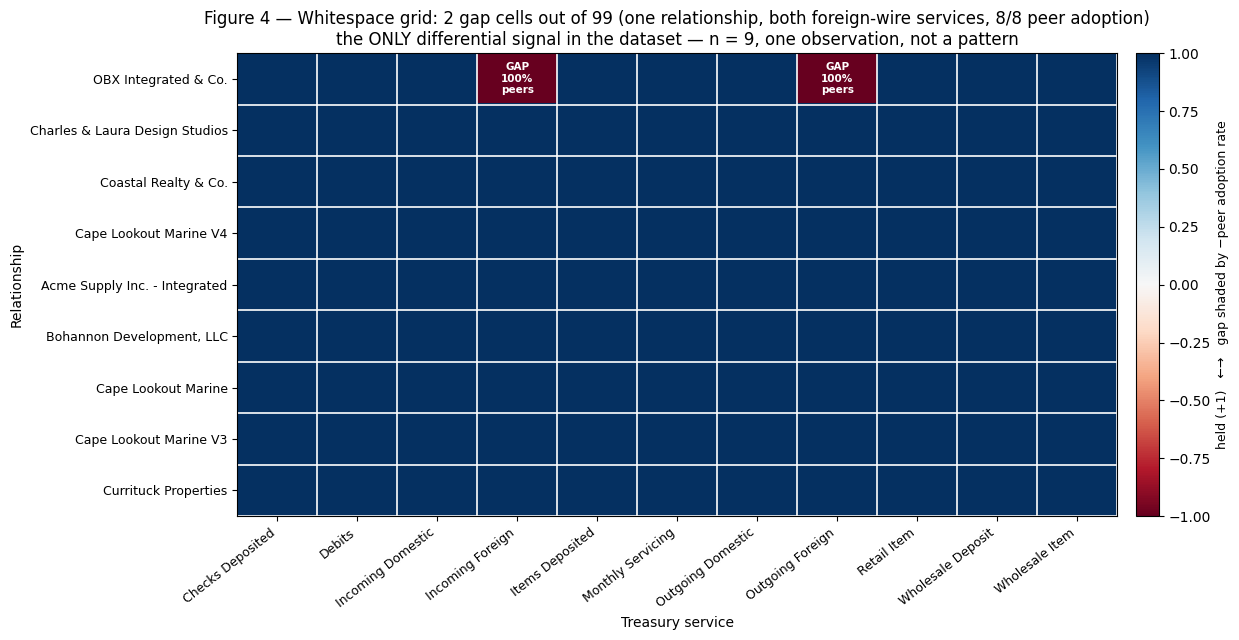

In [15]:
held = matrix.to_numpy(dtype=bool)
grid = np.zeros_like(held, dtype=float)
peer_rate = {
    (r.relationship_id, r.missing_service): r.peer_adoption_rate
    for r in gaps.itertuples(index=False)
}
row_index = list(matrix.index)
col_index = list(matrix.columns)
for i, rid in enumerate(row_index):
    for j, service in enumerate(col_index):
        grid[i, j] = 1.0 if held[i, j] else -peer_rate.get((rid, service), 0.0)

fig, ax = plt.subplots(figsize=(12.5, 6.5))
mesh = ax.imshow(grid, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(col_index)))
ax.set_xticklabels(col_index, rotation=38, ha="right", fontsize=9)
ax.set_yticks(np.arange(len(row_index)))
ax.set_yticklabels([labels[r] for r in row_index], fontsize=9)
ax.set_xticks(np.arange(-0.5, len(col_index), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(row_index), 1), minor=True)
ax.grid(which="minor", color="white", lw=1.2)
ax.tick_params(which="minor", length=0)
for i, rid in enumerate(row_index):
    for j, service in enumerate(col_index):
        if not held[i, j]:
            rate = peer_rate.get((rid, service), 0.0)
            ax.text(j, i, f"GAP\n{rate:.0%}\npeers", ha="center", va="center",
                    fontsize=7.5, fontweight="bold", color="white")
cbar = fig.colorbar(mesh, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("held (+1)   ←→   gap shaded by −peer adoption rate", fontsize=9)
ax.set_xlabel("Treasury service")
ax.set_ylabel("Relationship")
ax.set_title(
    "Figure 4 — Whitespace grid: 2 gap cells out of "
    f"{matrix.size} (one relationship, both foreign-wire services, 8/8 peer adoption)\n"
    "the ONLY differential signal in the dataset — n = 9, one observation, not a pattern",
    fontsize=12,
)
fig.tight_layout()
plt.show()

### Figure 5 — basket completeness ranking

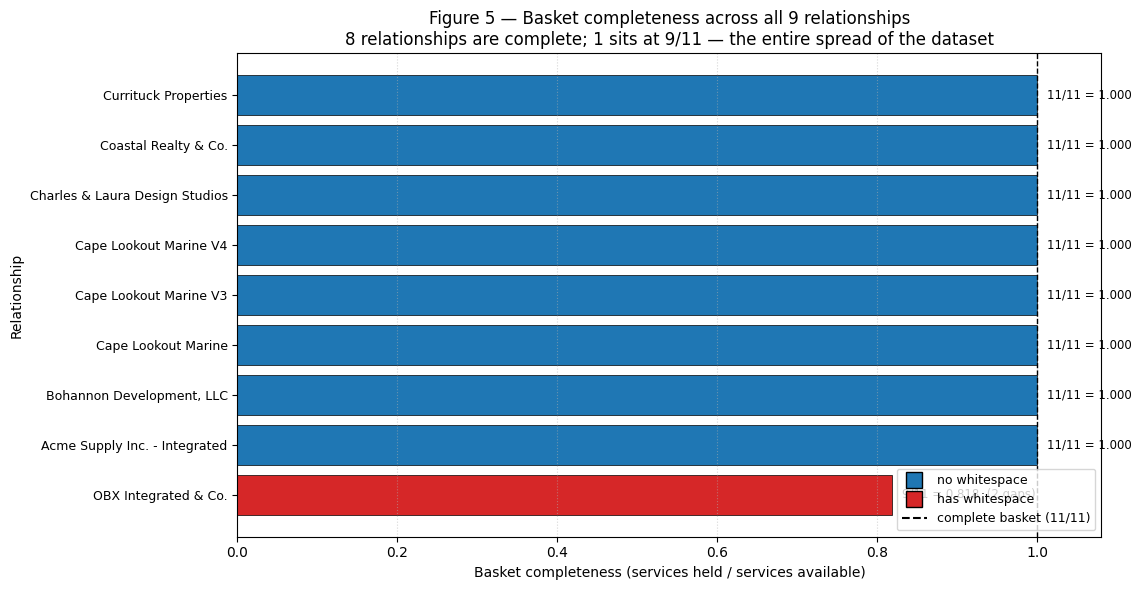

In [16]:
order = completeness.sort_values("basket_completeness", ascending=True)
y = np.arange(len(order))
bar_colors = ["#d62728" if g else "#1f77b4" for g in order["n_gaps"]]

fig, ax = plt.subplots(figsize=(11.5, 6))
ax.barh(y, order["basket_completeness"], color=bar_colors,
        edgecolor="black", linewidth=0.5)
ax.set_yticks(y)
ax.set_yticklabels(order["relationship_name"], fontsize=9)
ax.set_xlim(0, 1.08)
ax.axvline(1.0, ls="--", color="black", lw=1.0, label="complete basket (11/11)")
for yi, (frac, held_n, gap_n) in enumerate(
    zip(order["basket_completeness"], order["services_held"], order["n_gaps"])
):
    ax.text(frac + 0.012, yi, f"{held_n}/11 = {frac:.3f}"
            + (f"  ({gap_n} gap{'s' if gap_n != 1 else ''})" if gap_n else ""),
            va="center", fontsize=8.5)
handles = [
    plt.Line2D([], [], marker="s", color="w", markerfacecolor="#1f77b4",
               markeredgecolor="black", markersize=11, label="no whitespace"),
    plt.Line2D([], [], marker="s", color="w", markerfacecolor="#d62728",
               markeredgecolor="black", markersize=11, label="has whitespace"),
    plt.Line2D([], [], ls="--", color="black", label="complete basket (11/11)"),
]
ax.legend(handles=handles, loc="lower right", fontsize=9)
ax.set_xlabel("Basket completeness (services held / services available)")
ax.set_ylabel("Relationship")
ax.set_title(
    "Figure 5 — Basket completeness across all 9 relationships\n"
    "8 relationships are complete; 1 sits at 9/11 — the entire spread of the dataset",
    fontsize=12,
)
ax.grid(axis="x", ls=":", alpha=0.5)
fig.tight_layout()
plt.show()

---
# Conclusions

## What is actually concludable from this snapshot

Exactly one thing, and it is a lead rather than a result:

> **`OBX Integrated & Co.`** is the only one of the 9 relationships that does not hold
> `Incoming Foreign` or `Outgoing Foreign`. All 8 peers hold both. Its basket
> completeness is 9/11 = 0.818; every other relationship is 11/11 = 1.000.

Caveats that must travel with that sentence:

- It is **one observation at n = 9**. There is no statistical support: Fisher's exact on
  a 9-vs-8 split cannot reach p < 0.05 at this sample size.
- The two foreign-wire services co-occur perfectly (8/8, Jaccard = 1.0), so this is a
  single joint gap, not two independent gaps.
- The obvious alternative explanation — the relationship has no international payment
  need, or routes foreign wires through another provider — is **not testable with this
  data**. `ACTUAL_MONTHLY_UNITS`, `WAIVED_UNITS` and `YEARLY_VOLUME` are all NULL here.
- Action implied: ask a relationship manager whether the gap is a genuine cross-sell or
  a deliberate absence. Not: forecast revenue from it.

## What is NOT concludable

- **Nothing from centrality.** Degree, weighted degree, eigenvector and clustering are
  flat to ~6 decimal places and betweenness is identically 0. No service is a "hub",
  "bridge" or "gateway" in this graph.
- **Nothing from community detection.** Modularity Q ≈ 0; the returned partition is an
  arbitrary cut of a clique.
- **Nothing from threshold sensitivity.** The graph is complete below weight 1.0 and
  nearly empty above it. There is no graded structure to tune.
- **No cross-sell pattern, no product affinity, no segmentation.** With only two
  distinct basket signatures across 9 relationships, the dataset contains one bit of
  differential information and cannot support any of these claims.
- **No revenue conclusions.** All LockBox services carry 0.00 revenue, and
  `FTP_NET_REVENUE` and `STRATEGIC_NET_REVENUE` are row-for-row identical, so they are
  one measure and not two.

## Why whitespace analysis is the technique that survives small n

Of the five approaches in this investigation, whitespace/gap analysis is the only one
that **degrades gracefully**. Rule mining, lift ranking, significance testing and
clustering all estimate a *population* quantity from 9 draws, and at that size their
estimates are quantised to ninths and swamped by sampling noise — the metrics still
compute, but they are not identifiable. Whitespace analysis instead makes a
**per-entity descriptive statement** against an explicitly enumerated peer set. "This
relationship lacks a service that 8 of 8 named peers hold" is verifiable by inspection
and does not weaken as n shrinks; what shrinks is only the *generality* of the peer
benchmark, and that shrinkage is visible in the `peer_total` column rather than hidden
inside a p-value. It is also the only approach here that returns an answer attached to
an actionable unit — a named relationship — rather than to an abstract item pair.

## What graph MBA would reveal at scale

With thousands of relationships and a wider service catalogue, the same two
constructions become genuinely informative:

- **Sparse, graded edge weights.** Lift would span a real range, so threshold sweeps
  would reveal a backbone and a periphery instead of an all-or-nothing transition.
- **Meaningful centrality.** Betweenness would identify services that *bridge*
  otherwise-disconnected product families — the gateway products whose adoption opens a
  new segment. That is exactly the question Figure 3 cannot answer here.
- **Real communities.** Modularity well above 0 would carve the catalogue into product
  families discovered from behaviour rather than assumed from the service hierarchy,
  and those communities could be compared against the (provisional) `DDA` / `LockBox` /
  `Wire Transfer` groups for validation.
- **Segment-conditional whitespace.** Peer sets could be defined within segment, size
  band or industry instead of "all other relationships", turning the recommendation
  from a global completeness score into a conditional next-best-action with a
  measurable base rate — and, with enough relationships, a testable one.

The deliverable from this notebook is therefore the **method**: a parameterised graph
construction, an explicit degeneracy check, and a whitespace ranking that can be
re-pointed at a larger snapshot by changing the parameter cell.